# 06 · O test set

**Objetivo:** medir uma única vez, no test set, os seis sistemas registrados no [docs/EVALUATION.md](../docs/EVALUATION.md) ("Seleção e teste"), depois de o sistema escolhido ter sido registrado: o **hybrid search + reranker sem o cross-encoder**, escolhido no validation set em `04_reranker.ipynb`, Etapa 7.3.

**Regras deste notebook**
- **É o único notebook que usa o test set,** e ele roda depois de todas as decisões do projeto. A data da execução fica registrada no `docs/EVALUATION.md`.
- **Nada é treinado nem ajustado aqui:** os rerankers são os modelos salvos em `models/`, treinados só no train set (`uv run python -m wands_search.train_reranker`).
- **A escolha não muda com o resultado.** Se outro sistema for melhor no test set, isso é reportado como resultado; trocar a escolha seria usar o test set para escolher.
- O notebook pode ser reexecutado e reproduz as mesmas métricas (só a latência muda), mas nenhuma decisão depende dele.

**Como ler este notebook**
- Cada seção começa explicando a pergunta que ela responde e pode ser lida sozinha. As conclusões ficam logo abaixo da célula que as sustenta.
- Os termos técnicos ficam em inglês e estão definidos na seção "Termos usados no notebook"; são os mesmos de `04_reranker.ipynb`.

**Etapas**
1. As seis linhas no test set
2. O sistema escolhido contra as outras linhas
3. O validation set antecipou o test set?
4. Latência

## TL;DR

- **O sistema escolhido no validation set, o hybrid search + reranker sem o cross-encoder, também tem o maior NDCG@10 no test set: 0,824 [0,773; 0,870]** (Etapa 1). O test set rodou em 2026-11-09, com os modelos salvos em `models/` e sem nenhum ajuste.
- **Contra o hybrid search sozinho, ele sobe o NDCG@10 em +0,041 [0,020; 0,063], mas não o condensed NDCG@10 (−0,002 [−0,012; 0,009]),** e o judged@10 sobe +0,065. É o mesmo padrão do validation set: o ganho vem de trazer ao topo produtos com `label` (Etapa 2).
- **Contra o BM25 v2 + reranker, a diferença não se distingue de 0 no test set:** +0,010 [−0,008; 0,031] no NDCG@10. No validation set, a mesma comparação (com o cross-encoder no hybrid) excluía 0 (Etapa 2).
- **Tirar o cross-encoder continua sem custo:** o escolhido fica +0,003 [−0,008; 0,014] acima da versão com ele, e o ranking leva 27,1 ms na mediana, contra 376,8 ms com o cross-encoder, na execução salva (Etapas 2 e 4).
- **O validation set não foi otimista para o escolhido:** os seis sistemas têm NDCG@10 maior no test set (de +0,023 a +0,097), e a ordem é a mesma do validation set, exceto que o BM25 v2 + reranker passa a hybrid search (Etapa 3).

## Termos usados no notebook

| Termo | Significado | Exemplo |
|---|---|---|
| query | Texto que uma pessoa digitou na busca da loja (coluna `query` de `query.csv`). | "leather chair" |
| label | Julgamento humano de um par (query, produto): Exact, Partial ou Irrelevant. Produto **sem `label`**: nunca foi julgado para a query. | |
| split | Divisão das queries em **train set** (287; treinar e escolher parâmetros), **validation set** (97; comparar e escolher sistemas) e **test set** (95; medir uma única vez, aqui). | |
| retrieval | Primeira etapa: escolhe, no catalog inteiro, os 200 primeiros produtos. **BM25** (baseline), **BM25 v2** (plurais removidos, `product_features` limpas), **semantic search** (embeddings de `BAAI/bge-small-en-v1.5`) e **hybrid search** (RRF da BM25 v2 com a semantic search). | |
| reranker | Modelo LambdaMART (LightGBM) que reordena os 100 primeiros do retrieval. Aqui, os modelos salvos em `models/`. | |
| cross-encoder | Modelo pré-treinado que lê a query e o produto juntos; usado como feature em duas das seis linhas. | |
| paired bootstrap | Para comparar dois sistemas: diferença por query, sorteio das queries com reposição 2.000 vezes (seed 0), intervalo de 95% entre os percentis 2,5 e 97,5. Se o intervalo contém 0, não distinguimos os dois. | |

### Métricas

| Métrica | O que mede | Queries do test set |
|---|---|---|
| **NDCG@10** (principal) | Qualidade da ordem dos 10 primeiros, com gain Exact = 2, Partial = 1, Irrelevant e sem `label` = 0. | todas |
| **condensed NDCG@10** | NDCG@10 depois de tirar da lista os produtos sem `label`. | todas |
| **MRR@10** | 1 / posição do primeiro Exact nos 10 primeiros. | só as com Exact |
| **Capped Recall@100** | Exact nos 100 primeiros ÷ min(100, número de Exact da query). | só as com Exact |
| **Capped Recall@100 (Exact e Partial)** | O mesmo, com Exact e Partial como relevantes. Secundária. | todas |
| **judged@10** | Fração dos 10 primeiros que têm `label`. Não mede qualidade. | todas com resultado |
| **NDCG@5 / NDCG@15** | NDCG cortado em 5 e em 15. Só sensibilidade. | todas |

## Setup

Carrega os dados, monta os retrievals com os parâmetros escolhidos no train set (`wands_search.systems`) e o cálculo das features, com o cross-encoder (as linhas 4 e 6 o usam). Os embeddings dos produtos vêm de `cache/embeddings/`.

In [1]:
import platform
import time

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wands_search import data, evaluate, features, metrics, plots, ranking, reranker, retrieval, systems

plots.apply_style()
pd.set_option("display.max_colwidth", 80)

TEST_RUN_DATE = "2026-11-09"
products = data.load_products()
queries = data.load_queries()
labels = data.deduplicate_labels(data.load_labels())
labels_by_query = metrics.labels_by_query(labels)
query_split = evaluate.load_split()
validation_queries = evaluate.split_queries(queries, query_split, "validation")
test_queries = evaluate.split_queries(queries, query_split, "test", allow_test=True)

start = time.perf_counter()
retrievers = systems.build_systems(products)
baseline_index = retrieval.build_single_field_index(products, **retrieval.BASELINE_TEXT)  # BM25 baseline, k1 = 1.2, b = 0.75
cross_encoder = features.FastEmbedCrossEncoder()
feature_builder = features.build_feature_builder(products, retrievers, cross_encoder)
RETRIEVALS = {"BM25": baseline_index, "BM25 v2": retrievers.v2_index, "semantic search": retrievers.semantic_index,
              "hybrid": retrievers.hybrid_index}
RERANKED_RETRIEVALS = {"BM25 v2": retrievers.v2_index, "hybrid": retrievers.hybrid_index}
# The six rows registered in docs/EVALUATION.md: (retrieval, saved model or None).
REGISTERED_ROWS = {
    "BM25": ("BM25", None),
    "semantic search": ("semantic search", None),
    "hybrid search": ("hybrid", None),
    "BM25 v2 + reranker": ("BM25 v2", "bm25_v2_reranker"),
    "hybrid search + reranker without cross-encoder (selected)": ("hybrid", "hybrid_reranker_no_cross_encoder"),
    "hybrid search + reranker (reported)": ("hybrid", "hybrid_reranker"),
}
SELECTED_ROW = "hybrid search + reranker without cross-encoder (selected)"
saved_models = {model_name: reranker.load_model(model_name) for _, model_name in REGISTERED_ROWS.values() if model_name}
print(f"set up in {time.perf_counter() - start:.0f} s | lightgbm {lightgbm.__version__} | machine: {platform.platform()} ({platform.processor()})")
print("saved models: " + ", ".join(f"{name} ({len(metadata['feature_columns'])} features, trained on {metadata['train_queries']} train queries)"
                                   for name, (_, metadata) in saved_models.items()))
with_exact = lambda frame: sum(any(label == "Exact" for label in labels_by_query.get(query_id, {}).values()) for query_id in frame["query_id"])
print(f"validation set: {len(validation_queries)} queries, {with_exact(validation_queries)} with Exact | "
      f"test set: {len(test_queries)} queries, {with_exact(test_queries)} with Exact")

set up in 51 s | lightgbm 4.7.0 | machine: macOS-15.7.4-x86_64-i386-64bit-Mach-O (i386)
saved models: bm25_v2_reranker (25 features, trained on 287 train queries), hybrid_reranker_no_cross_encoder (29 features, trained on 287 train queries), hybrid_reranker (30 features, trained on 287 train queries)
validation set: 97 queries, 77 with Exact | test set: 95 queries, 75 with Exact


## Etapa 1 · As seis linhas no test set

Cada linha roda nas 95 queries do test set: os retrievals devolvem os 200 primeiros; os rerankers reordenam os 100 primeiros com o modelo salvo. Calculamos as mesmas métricas do validation set. As mesmas seis linhas também rodam no validation set, com os mesmos modelos, para a comparação da Etapa 3; os números do validation set devem ser iguais aos da tabela final do `04_reranker.ipynb`, Etapa 7.1.

In [2]:
def registered_metrics(query_frame):
    # Per-query metrics of the six registered rows on one set, with the saved models.
    runs = {name: evaluate.run_system(lambda query_text, k, index=index: index.search(query_text, k)["product_id"].tolist(),
                                      query_frame) for name, index in RETRIEVALS.items()}
    reranked_runs, tables, _ = features.candidate_features(RERANKED_RETRIEVALS, feature_builder, query_frame, labels_by_query)
    per_query = {}
    for row, (retrieval_name, model_name) in REGISTERED_ROWS.items():
        if model_name is None:
            per_query[row] = metrics.evaluate_run(runs[retrieval_name][0], labels_by_query, metrics.SENSITIVITY_NDCG_CUTOFFS)
        else:
            model, metadata = saved_models[model_name]
            scores = reranker.predict(model, tables[retrieval_name], metadata["feature_columns"])
            per_query[row] = reranker.evaluate_scores(reranked_runs[retrieval_name], tables[retrieval_name], scores, labels_by_query)
    retrieval_latency = {name: latency for name, (_, latency) in runs.items()}
    return per_query, reranked_runs, retrieval_latency


start = time.perf_counter()
validation_per_query, _, _ = registered_metrics(validation_queries)
test_per_query, test_runs, test_retrieval_latency = registered_metrics(test_queries)
print(f"six rows on the validation set and on the test set in {time.perf_counter() - start:.0f} s")

CI_METRICS = ["ndcg@10", "condensed_ndcg@10", "mrr@10", "capped_recall@100"]
MEAN_METRICS = ["capped_recall@100_exact_partial", "judged@10", "ndcg@5", "ndcg@15"]
test_table = pd.DataFrame({
    row: {
        **{metric: evaluate.format_ci(*evaluate.summary_table(per_query[[metric]]).loc[metric, ["mean", "ci_low", "ci_high"]])
           for metric in CI_METRICS},
        **{metric: f"{per_query[metric].mean():.3f}" for metric in MEAN_METRICS},
        "validation NDCG@10": f"{validation_per_query[row]['ndcg@10'].mean():.3f}",
    } for row, per_query in test_per_query.items()
}).T.rename_axis("system")
plots.table(test_table, f"Test set ({TEST_RUN_DATE}): the six registered systems on the 95 test queries", max_text_length=60,
            note="Mean with 95% bootstrap interval for the first four metrics; other columns: means. MRR@10 and Capped Recall@100: "
                 "test queries with Exact; capped_recall@100_exact_partial: Exact and Partial count (95 queries). validation NDCG@10: "
                 "the same system and saved model on the 97 validation queries. Rerankers: models saved in models/, trained on the "
                 "train set only.")

six rows on the validation set and on the test set in 83 s


,ndcg@10,condensed_ndcg@10,mrr@10,capped_recall@100,capped_recall@100_exact_partial,judged@10,ndcg@5,ndcg@15,validation NDCG@10
system,,,,,,,,,
BM25,0.717 [0.656; 0.769],0.825 [0.776; 0.867],0.763 [0.676; 0.845],0.703 [0.629; 0.773],0.638,0.833,0.736,0.712,0.620
semantic search,0.747 [0.691; 0.799],0.849 [0.803; 0.888],0.736 [0.643; 0.820],0.712 [0.644; 0.778],0.661,0.836,0.755,0.732,0.725
hybrid search,0.783 [0.724; 0.835],0.857 [0.812; 0.895],0.790 [0.707; 0.869],0.760 [0.695; 0.820],0.700,0.874,0.786,0.774,0.747
BM25 v2 + reranker,0.813 [0.758; 0.861],0.845 [0.793; 0.890],0.782 [0.693; 0.859],0.736 [0.666; 0.798],0.662,0.925,0.820,0.807,0.744
hybrid search + reranker without cross-encoder (selected),0.824 [0.773; 0.870],0.856 [0.808; 0.896],0.776 [0.687; 0.857],0.760 [0.695; 0.820],0.700,0.939,0.830,0.815,0.776
hybrid search + reranker (reported),0.821 [0.770; 0.867],0.856 [0.808; 0.897],0.776 [0.690; 0.857],0.760 [0.695; 0.820],0.700,0.929,0.828,0.817,0.772


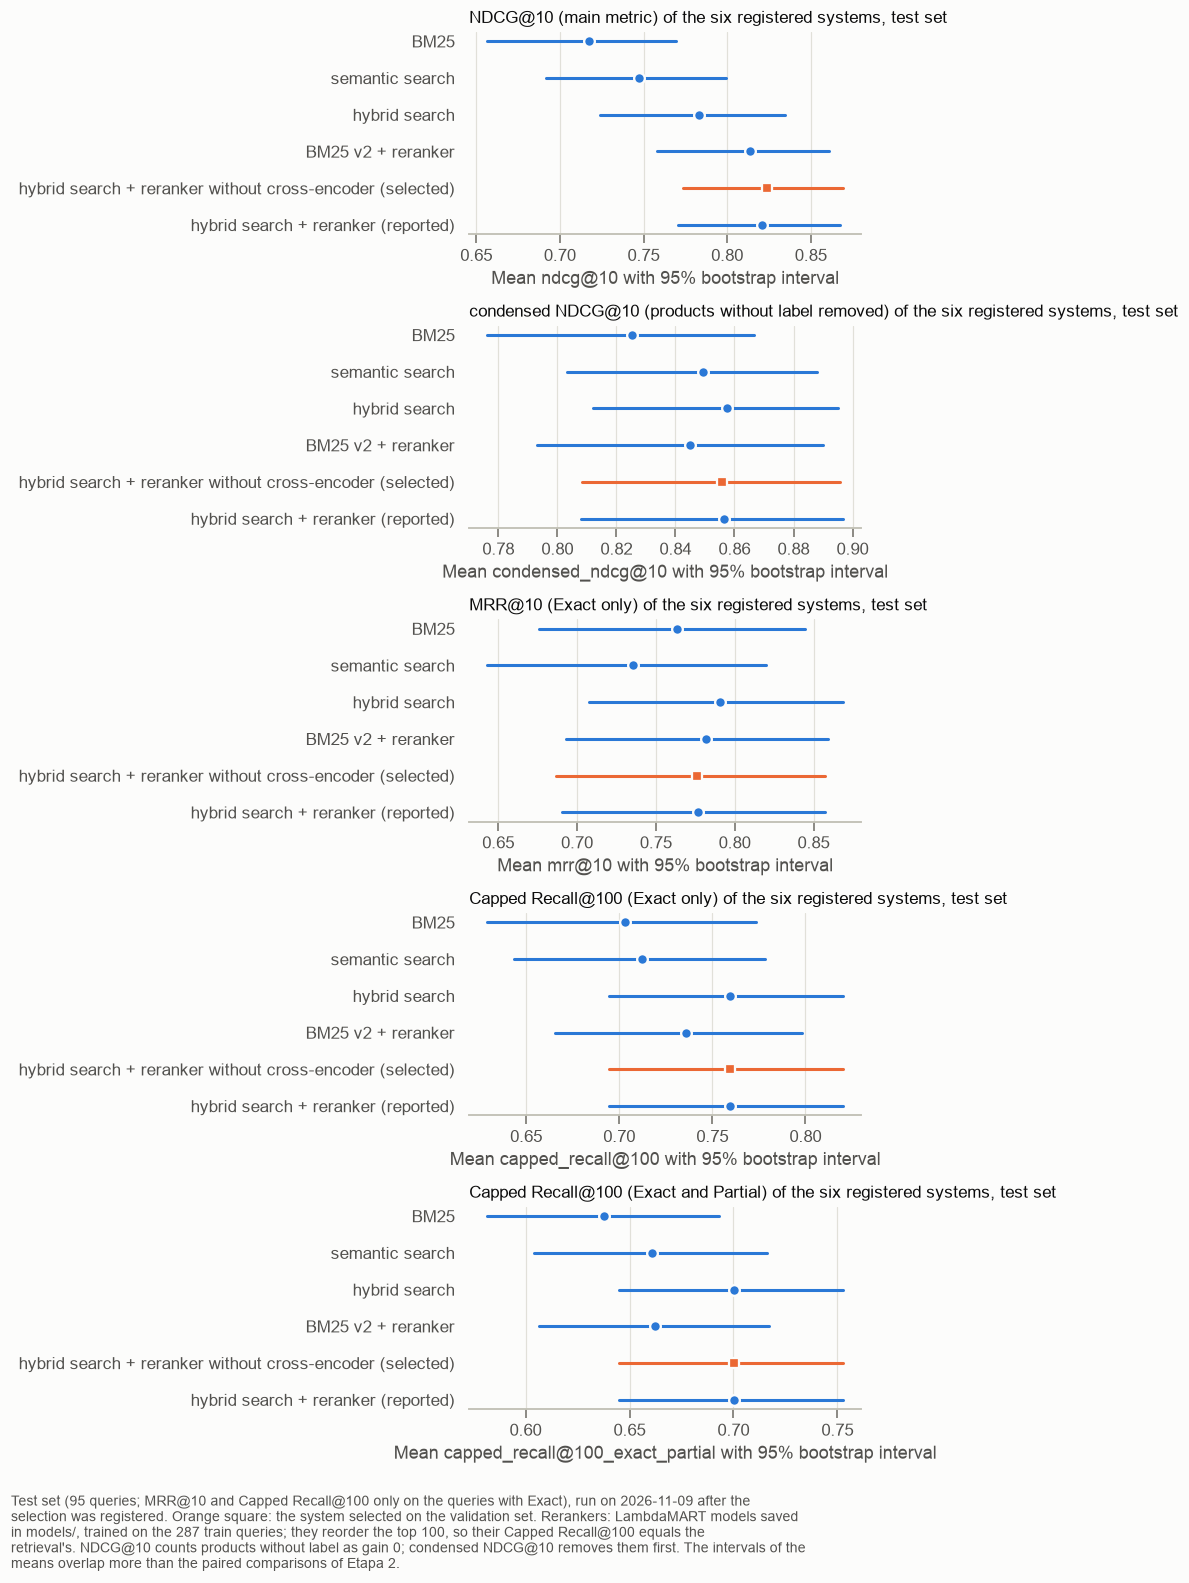

In [3]:
PLOT_METRICS = {"ndcg@10": "NDCG@10 (main metric)", "condensed_ndcg@10": "condensed NDCG@10 (products without label removed)",
                "mrr@10": "MRR@10 (Exact only)", "capped_recall@100": "Capped Recall@100 (Exact only)",
                "capped_recall@100_exact_partial": "Capped Recall@100 (Exact and Partial)"}
rows = list(REGISTERED_ROWS)
fig, axes = plt.subplots(len(PLOT_METRICS), 1, figsize=(8, 13.5))
for ax, (metric, title) in zip(axes, PLOT_METRICS.items()):
    summaries = [evaluate.summary_table(test_per_query[row][[metric]]).loc[metric] for row in rows]
    plots.system_interval_plot(ax, rows, [s["mean"] for s in summaries], [s["ci_low"] for s in summaries],
                               [s["ci_high"] for s in summaries], highlight=SELECTED_ROW)
    ax.set_title(f"{title} of the six registered systems, test set")
    ax.set_xlabel(f"Mean {metric} with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    f"Test set (95 queries; MRR@10 and Capped Recall@100 only on the queries with Exact), run on {TEST_RUN_DATE} after the selection was "
    "registered. Orange square: the system selected on the validation set. Rerankers: LambdaMART models saved in models/, trained on the "
    "287 train queries; they reorder the top 100, so their Capped Recall@100 equals the retrieval's. NDCG@10 counts products without "
    "label as gain 0; condensed NDCG@10 removes them first. The intervals of the means overlap more than the paired comparisons of Etapa 2."
))
plt.show()

A função `registered_metrics` fica no notebook porque só este notebook a usa, para o validation set e o test set.

**Resultados**
- **O maior NDCG@10 do test set é o do sistema escolhido, 0,824 [0,773; 0,870],** seguido do hybrid search + reranker com o cross-encoder (0,821) e do BM25 v2 + reranker (0,813). A hybrid search sozinha tem 0,783, a semantic search 0,747 e a BM25 0,717.
- **No condensed NDCG@10, as seis linhas ficam entre 0,825 e 0,857,** com a hybrid search sozinha (0,857) no mesmo nível dos rerankers sobre ela (0,856).
- **O judged@10 dos rerankers fica entre 0,925 e 0,939,** contra 0,833 a 0,874 dos retrievals sozinhos.
- **No MRR@10, a hybrid search sozinha tem a maior média (0,790);** os rerankers ficam entre 0,776 e 0,782.
- **A cobertura repete o validation set:** Capped Recall@100 de 0,760 na hybrid search (e nos rerankers sobre ela), 0,736 no BM25 v2 + reranker, 0,712 na semantic search e 0,703 na BM25; com Exact e Partial, 0,700, 0,662, 0,661 e 0,638.
- **No validation set, as seis linhas reproduzem a tabela final do `04_reranker.ipynb`** (coluna "validation NDCG@10"): os modelos salvos são os da seleção.

## Etapa 2 · O sistema escolhido contra as outras linhas

Diferença pareada (escolhido − outro) nas 95 queries do test set, com o paired bootstrap, como em todas as comparações do projeto. É uma descrição: a escolha já foi feita no validation set.

,ndcg@10,condensed_ndcg@10,mrr@10,judged@10
selected − system,,,,
BM25,0.106 [0.071; 0.144],0.031 [0.009; 0.054],0.013 [-0.064; 0.088],0.106 [0.066; 0.149]
semantic search,0.076 [0.050; 0.107],0.006 [-0.009; 0.023],0.040 [-0.022; 0.107],0.103 [0.071; 0.141]
hybrid search,0.041 [0.020; 0.063],-0.002 [-0.012; 0.009],-0.014 [-0.078; 0.051],0.065 [0.038; 0.099]
BM25 v2 + reranker,0.010 [-0.008; 0.031],0.011 [-0.004; 0.028],-0.006 [-0.059; 0.051],0.014 [-0.005; 0.034]
hybrid search + reranker (reported),0.003 [-0.008; 0.014],-0.001 [-0.008; 0.007],-0.000 [-0.039; 0.038],0.009 [0.000; 0.020]


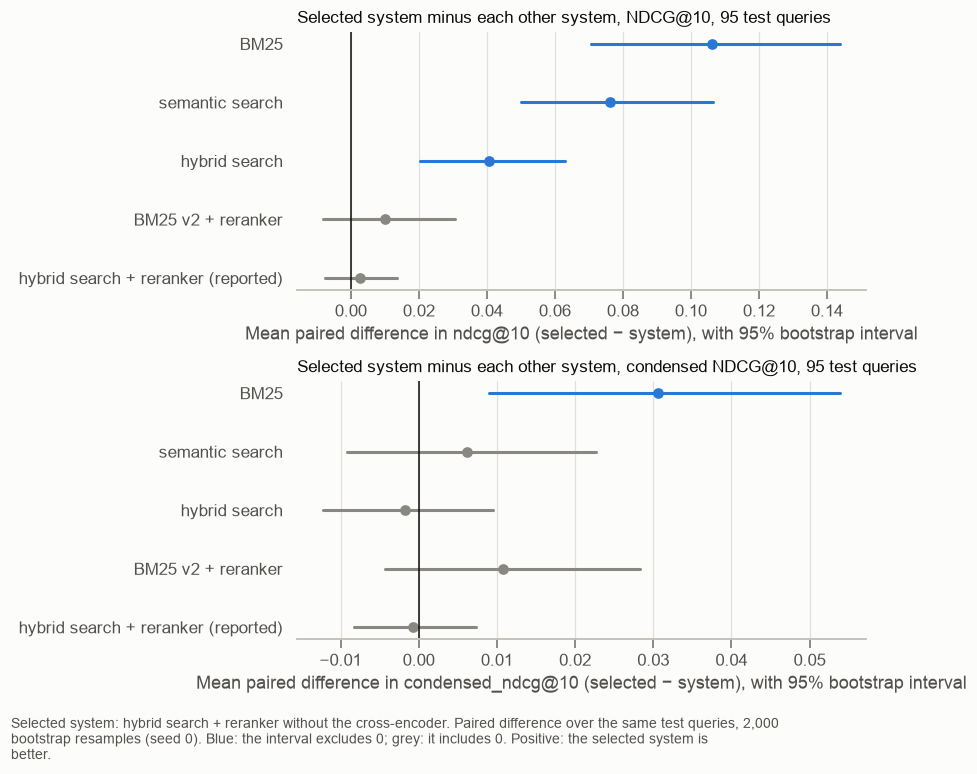

In [4]:
COMPARISON_METRICS = ["ndcg@10", "condensed_ndcg@10", "mrr@10", "judged@10"]
test_comparisons = {
    other: evaluate.compare_systems(test_per_query[SELECTED_ROW][COMPARISON_METRICS], test_per_query[other][COMPARISON_METRICS],
                                    COMPARISON_METRICS, name_a="selected", name_b="other")
    for other in REGISTERED_ROWS if other != SELECTED_ROW
}
display(plots.table(pd.DataFrame({other: comparison["difference_ci"] for other, comparison in test_comparisons.items()}).T
                    .rename_axis("selected − system"), "Selected system minus each other system on the 95 test queries",
                    note="Mean paired difference with 95% paired bootstrap interval (2,000 resamples, seed 0). MRR@10: test queries with Exact."))

others = [row for row in REGISTERED_ROWS if row != SELECTED_ROW]
fig, axes = plt.subplots(2, 1, figsize=(8, 6.5))
for ax, metric, title in zip(axes, ["ndcg@10", "condensed_ndcg@10"], ["NDCG@10", "condensed NDCG@10"]):
    plots.difference_plot(ax, others, [test_comparisons[o].loc[metric, "difference"] for o in others],
                          [test_comparisons[o].loc[metric, "difference_ci_low"] for o in others],
                          [test_comparisons[o].loc[metric, "difference_ci_high"] for o in others])
    ax.set_title(f"Selected system minus each other system, {title}, 95 test queries")
    ax.set_xlabel(f"Mean paired difference in {metric} (selected − system), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Selected system: hybrid search + reranker without the cross-encoder. Paired difference over the same test queries, 2,000 bootstrap "
    "resamples (seed 0). Blue: the interval excludes 0; grey: it includes 0. Positive: the selected system is better."
))
plt.show()

**Resultados**
- **O escolhido supera a BM25, a semantic search e a hybrid search no NDCG@10, com intervalos que excluem 0:** +0,106 [0,071; 0,144], +0,076 [0,050; 0,107] e +0,041 [0,020; 0,063].
- **No condensed NDCG@10, só a diferença para a BM25 exclui 0** (+0,031 [0,009; 0,054]); contra a semantic search e a hybrid search, +0,006 [−0,009; 0,023] e −0,002 [−0,012; 0,009].
- **Contra o BM25 v2 + reranker, a diferença inclui 0:** NDCG@10 +0,010 [−0,008; 0,031], condensed +0,011 [−0,004; 0,028]. No validation set, o hybrid search + reranker superava o BM25 v2 + reranker com intervalo que excluía 0 (+0,028 [0,010; 0,048], `04_reranker.ipynb`, Etapa 4.3).
- **Contra a versão com o cross-encoder, a diferença inclui 0:** +0,003 [−0,008; 0,014].
- **Nenhuma diferença de MRR@10 exclui 0.**

**O que isso implica (nossa interpretação)**
- O test set confirma as duas leituras centrais do validation set: o reranker sobe o NDCG@10 sobre a hybrid search sobretudo trazendo ao topo produtos com `label`, e o cross-encoder não agrega.
- A vantagem do embedding model sobre o sistema lexical com reranker, clara no validation set, fica menor e indistinguível de 0 no test set. Com cerca de 95 queries por set, diferenças de 0,01 a 0,03 ficam perto do limite do que o bootstrap distingue.

**Limitações**
- Muitas comparações, sem correção para comparações múltiplas; são descrição, não testes de aprovação.

## Etapa 3 · O validation set antecipou o test set?

Comparamos o NDCG@10 de cada linha no validation set (97 queries) e no test set (95 queries). Os dois sets têm queries diferentes, então a diferença não é pareada; o que interessa é se os sistemas ficam na mesma ordem e se o escolhido perde muito no test set, o que indicaria uma escolha otimista.

,validation,test,validation (condensed),test (condensed),test − validation
system,,,,,
BM25,0.620,0.717,0.781,0.825,0.097
semantic search,0.725,0.747,0.836,0.849,0.023
hybrid search,0.747,0.783,0.834,0.857,0.036
BM25 v2 + reranker,0.744,0.813,0.802,0.845,0.070
hybrid search + reranker without cross-encoder (selected),0.776,0.824,0.831,0.856,0.047
hybrid search + reranker (reported),0.772,0.821,0.832,0.856,0.049


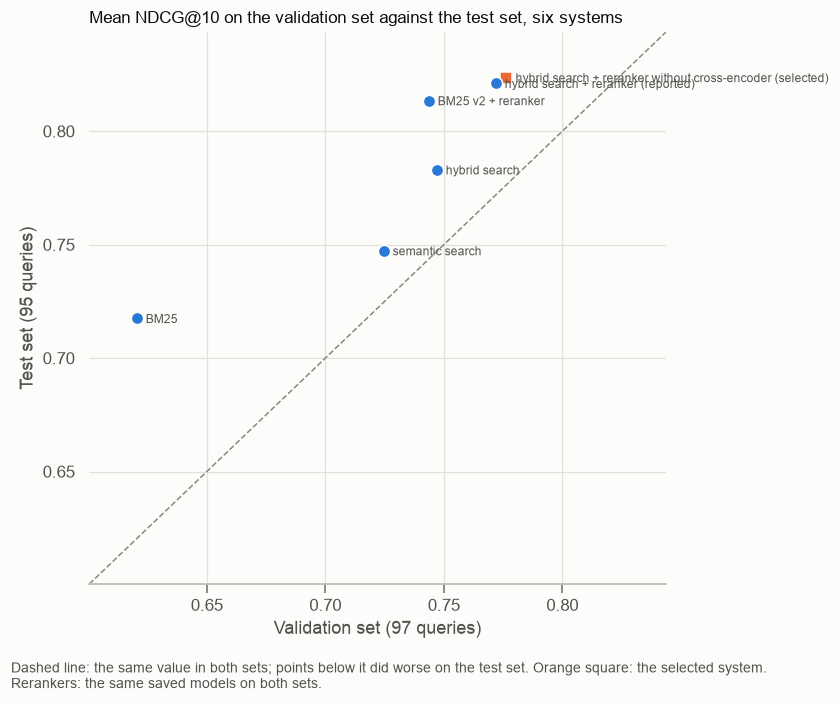

In [5]:
validation_test = pd.DataFrame({
    row: {"validation": validation_per_query[row]["ndcg@10"].mean(), "test": test_per_query[row]["ndcg@10"].mean(),
          "validation (condensed)": validation_per_query[row]["condensed_ndcg@10"].mean(),
          "test (condensed)": test_per_query[row]["condensed_ndcg@10"].mean()}
    for row in REGISTERED_ROWS
}).T
validation_test["test − validation"] = validation_test["test"] - validation_test["validation"]
display(plots.table(validation_test.rename_axis("system"), "Mean NDCG@10 and condensed NDCG@10 of each system on the validation and test sets",
                    precision=3, note="Different queries in each set (97 validation, 95 test), so the difference is not paired."))

fig, ax = plt.subplots(figsize=(7.5, 6))
for row, values in validation_test.iterrows():
    is_selected = row == SELECTED_ROW
    ax.plot(values["validation"], values["test"], marker="s" if is_selected else "o", markersize=8, linestyle="none",
            color=plots.SERIES_2 if is_selected else plots.SERIES_1, markeredgecolor=plots.SURFACE)
    ax.annotate(row, (values["validation"], values["test"]), xytext=(6, -3), textcoords="offset points", fontsize=8,
                color=plots.SECONDARY_INK)
limits = [validation_test[["validation", "test"]].min().min() - 0.02, validation_test[["validation", "test"]].max().max() + 0.02]
ax.plot(limits, limits, color=plots.MUTED_INK, linewidth=1, linestyle="--")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_title("Mean NDCG@10 on the validation set against the test set, six systems")
ax.set_xlabel("Validation set (97 queries)")
ax.set_ylabel("Test set (95 queries)")
fig.tight_layout()
plots.add_caption(fig, "Dashed line: the same value in both sets; points below it did worse on the test set. Orange square: the selected "
                       "system. Rerankers: the same saved models on both sets.")
plt.show()

**Resultados**
- **Os seis sistemas têm NDCG@10 maior no test set que no validation set:** de +0,023 (semantic search) a +0,097 (BM25); o escolhido sobe +0,047.
- **A ordem dos sistemas se mantém, com uma troca:** o BM25 v2 + reranker fica abaixo da hybrid search no validation set (0,744 contra 0,747) e acima no test set (0,813 contra 0,783).

**O que isso implica (nossa interpretação)**
- O test set parece mais fácil para todos os sistemas, o que é variação entre amostras de cerca de 95 queries, e não efeito da seleção: os sistemas que não foram escolhidos também sobem.
- O escolhido não perde posição no test set, então a seleção no validation set não foi otimista a ponto de mudar a conclusão.

**Limitações**
- Validation set e test set têm queries diferentes; a diferença entre eles não é pareada e não tem intervalo.

## Etapa 4 · Latência

Tempo de cada etapa nas 95 queries do test set, depois de 20 buscas de aquecimento: o retrieval dos 200 primeiros e o ranking dos 100 primeiros (features e nota do modelo salvo), separados. Os números mudam a cada execução e dependem da máquina (CPU, sem GPU).

In [6]:
ranking_latency = {}
for row, (retrieval_name, model_name) in REGISTERED_ROWS.items():
    if model_name is None:
        continue
    model, metadata = saved_models[model_name]
    columns = metadata["feature_columns"]
    feature_builder.cross_encoder = cross_encoder if "cross_encoder_score" in columns else None
    ranking_latency[row] = reranker.ranking_latency(feature_builder, model, columns, test_runs[retrieval_name], test_queries,
                                                    use_embeddings=bool(set(columns) & set(features.EMBEDDING_FEATURES)))
feature_builder.cross_encoder = cross_encoder
latency_table = pd.DataFrame({
    row: {"retrieval p50": test_retrieval_latency[retrieval_name].quantile(0.5),
          "retrieval p95": test_retrieval_latency[retrieval_name].quantile(0.95),
          "ranking p50": ranking_latency[row].quantile(0.5) if row in ranking_latency else np.nan,
          "ranking p95": ranking_latency[row].quantile(0.95) if row in ranking_latency else np.nan}
    for row, (retrieval_name, _) in REGISTERED_ROWS.items()
}).T.rename_axis("system")
plots.table(latency_table, "Latency of one search in milliseconds, retrieval and ranking, 95 test queries", precision=1,
            note=f"One process on {platform.platform()} ({platform.processor()}), CPU only, after {evaluate.WARMUP_QUERIES} warm-up "
                 "searches. Retrieval: top 200. Ranking: features of the top 100 and the score of the saved model; empty for the "
                 "systems without a reranker.")

,retrieval p50,retrieval p95,ranking p50,ranking p95
system,,,,
BM25,0.9,3.6,null,null
semantic search,7.5,8.8,null,null
hybrid search,9.0,11.7,null,null
BM25 v2 + reranker,0.9,3.2,380.9,477.5
hybrid search + reranker without cross-encoder (selected),9.0,11.7,27.1,32.1
hybrid search + reranker (reported),9.0,11.7,376.8,487.7


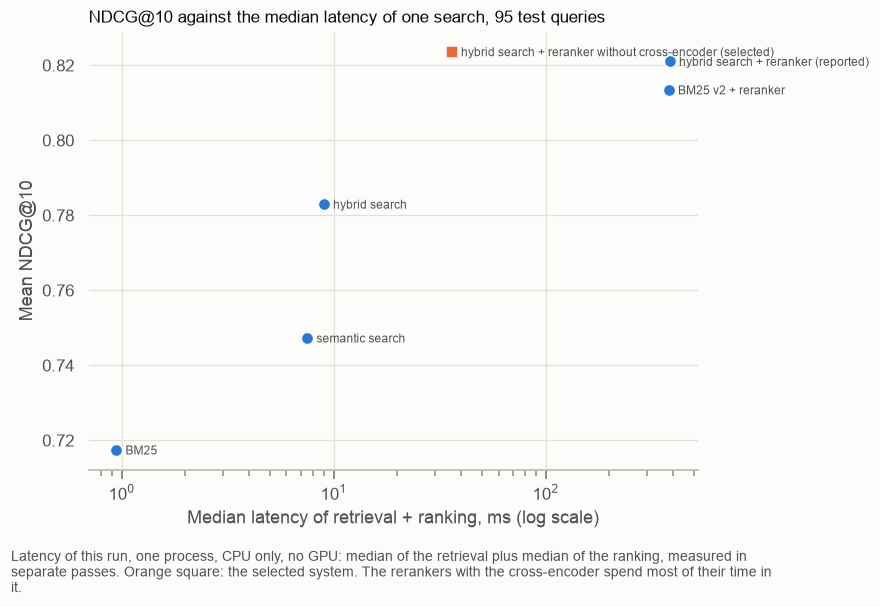

In [7]:
latency_points = pd.DataFrame({
    row: {"ndcg@10": test_per_query[row]["ndcg@10"].mean(),
          "total p50 (ms)": latency_table.loc[row, "retrieval p50"] + (0.0 if np.isnan(latency_table.loc[row, "ranking p50"])
                                                                       else latency_table.loc[row, "ranking p50"])}
    for row in REGISTERED_ROWS
}).T
fig, ax = plt.subplots(figsize=(8, 5))
for row, values in latency_points.iterrows():
    is_selected = row == SELECTED_ROW
    ax.plot(values["total p50 (ms)"], values["ndcg@10"], marker="s" if is_selected else "o", markersize=8, linestyle="none",
            color=plots.SERIES_2 if is_selected else plots.SERIES_1, markeredgecolor=plots.SURFACE)
    ax.annotate(row, (values["total p50 (ms)"], values["ndcg@10"]), xytext=(6, -3), textcoords="offset points", fontsize=8,
                color=plots.SECONDARY_INK)
ax.set_xscale("log")
ax.set_title("NDCG@10 against the median latency of one search, 95 test queries")
ax.set_xlabel("Median latency of retrieval + ranking, ms (log scale)")
ax.set_ylabel("Mean NDCG@10")
fig.tight_layout()
plots.add_caption(fig, (
    "Latency of this run, one process, CPU only, no GPU: median of the retrieval plus median of the ranking, measured in separate "
    "passes. Orange square: the selected system. The rerankers with the cross-encoder spend most of their time in it."
))
plt.show()

**Resultados**
- **Na execução salva, o ranking do sistema escolhido leva 27,1 ms na mediana e 32,1 ms no p95;** com o cross-encoder, 376,8 ms e 487,7 ms (hybrid) e 380,9 ms e 477,5 ms (BM25 v2).
- **O retrieval leva 0,9 ms (BM25), 7,5 ms (semantic search) e 9,0 ms (hybrid search) na mediana;** a busca completa do escolhido fica em cerca de 36 ms.

**Limitações**
- Uma única execução numa única máquina, sem GPU.